In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy import stats
from mlxtend.preprocessing import minmax_scaling

%matplotlib inline
np.random.seed(0)

In [2]:
# read in all our data
ks2017_data = pd.read_csv("../datasets/kickstarter-projects/ks-projects-201801.csv")
ks2017_data.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [3]:
### SCALING
# select the usd_goal_real column
original_data = pd.DataFrame(ks2017_data.usd_goal_real)

# scale the goals from 0 to 1
scaled_data = minmax_scaling(original_data, columns=['usd_goal_real'])

print('Original data\nPreview:\n', original_data.head())
print(f'Minimum value: {original_data.min().astype(float).item()}\n'
      f'Maximum value: {original_data.max().astype(float).item()}')
print('_'*30)

print('\nScaled data\nPreview:\n', scaled_data.head())
print(f'Minimum value: {scaled_data.min().astype(float).item()}\n'
      f'Maximum value: {scaled_data.max().astype(float).item()}')

Original data
Preview:
    usd_goal_real
0        1533.95
1       30000.00
2       45000.00
3        5000.00
4       19500.00
Minimum value: 0.01
Maximum value: 166361390.71
______________________________

Scaled data
Preview:
    usd_goal_real
0       0.000009
1       0.000180
2       0.000270
3       0.000030
4       0.000117
Minimum value: 0.0
Maximum value: 1.0


In [4]:
original_goal_data = pd.DataFrame(ks2017_data.goal)

# Create a new DataFrame scaled_goal_data with values scaled between 0 and 1
scaled_goal_data = minmax_scaling(original_goal_data, columns=['goal'])

In [6]:
### NORMALISATION
# get the index of all positive pledges (Box-Cox only takes positive values)
index_of_positive_pledges = ks2017_data.usd_pledged_real > 0

# get only positive pledges (using their indexes)
positive_pledges = ks2017_data.usd_pledged_real.loc[index_of_positive_pledges]

# normalize the pledges (w/ Box-Cox)
normalized_pledges = pd.Series(stats.boxcox(positive_pledges)[0], 
                               name='usd_pledged_real', index=positive_pledges.index)

print('Original data\nPreview:\n', positive_pledges.head())
print('Minimum value:', positive_pledges.min().astype(float).item(),
      '\nMaximum value:', positive_pledges.max().astype(float).item())
print('_'*30)

print('\nNormalized data\nPreview:\n', normalized_pledges.head())
print('Minimum value:', normalized_pledges.min().astype(float).item(),
      '\nMaximum value:', normalized_pledges.max().astype(float).item())

Original data
Preview:
 1     2421.0
2      220.0
3        1.0
4     1283.0
5    52375.0
Name: usd_pledged_real, dtype: float64
Minimum value: 0.45 
Maximum value: 20338986.27
______________________________

Normalized data
Preview:
 1    10.165142
2     6.468598
3     0.000000
4     9.129277
5    15.836852
Name: usd_pledged_real, dtype: float64
Minimum value: -0.7779954154530838 
Maximum value: 30.690537060647134


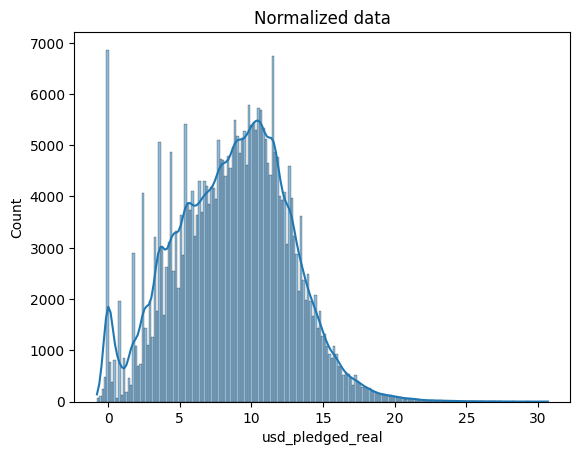

In [7]:
# plot normalized data
ax = sns.histplot(normalized_pledges, kde=True)
ax.set_title("Normalized data")
plt.show()

In [13]:
# get the index of all positive pledges (Box-Cox only takes positive values)
index_of_positive_pledges = ks2017_data.pledged > 0

# get only positive pledges (using their indexes)
positive_pledges = ks2017_data.pledged.loc[index_of_positive_pledges]

# normalize the pledges (w/ Box-Cox)
normalized_pledges = pd.Series(stats.boxcox(positive_pledges)[0], 
                               name='pledged', index=positive_pledges.index)

print('Original data\nPreview:\n', positive_pledges.head())
print('Minimum value:', positive_pledges.min().astype(float).item(),
      '\nMaximum value:', positive_pledges.max().astype(float).item())
print('_'*30)

print('\nNormalized data\nPreview:\n', normalized_pledges.head())
print('Minimum value:', normalized_pledges.min().astype(float).item(),
      '\nMaximum value:', normalized_pledges.max().astype(float).item())

Original data
Preview:
 1     2421.0
2      220.0
3        1.0
4     1283.0
5    52375.0
Name: pledged, dtype: float64
Minimum value: 1.0 
Maximum value: 20338986.27
______________________________

Normalized data
Preview:
 1    10.013887
2     6.403368
3     0.000000
4     9.005193
5    15.499596
Name: pledged, dtype: float64
Minimum value: 0.0 
Maximum value: 29.630308617318825


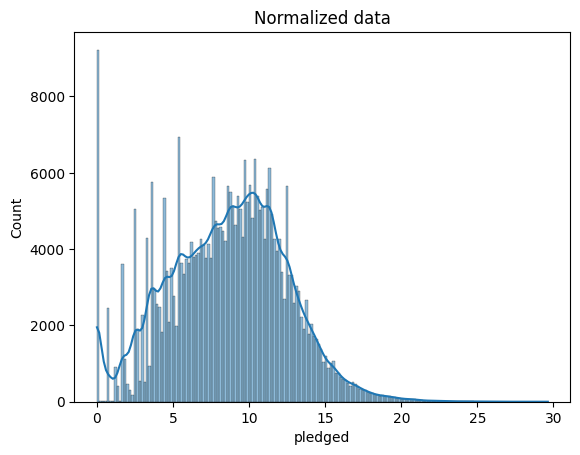

In [14]:
# plot normalized data
ax = sns.histplot(normalized_pledges, kde=True)
ax.set_title("Normalized data")
plt.show()